# Experiment 7 – Fine-tuning ConvNeXt-Tiny

**Goal:** classify the 200 classes as well as possible with **ConvNeXt-Tiny**, the backbone that won the frozen
comparison (E6 in `ResNet_improved.ipynb`).

| experiment | set-up | val accuracy |
|---|---|---|
| E5 | ResNet50, fine-tuned conv3–conv5, E5 recipe | 58.6 % |
| E6 | ResNet50 frozen + head | 53.5 % |
| E6 | **ConvNeXt-Tiny frozen + head** | **65.2 %** |
| **E7** | **ConvNeXt-Tiny fully fine-tuned, E5 recipe** | this notebook |

**Recipe** (from E5): augmentation, MixUp, label smoothing, AdamW with weight decay, warmup + cosine learning rate,
mixed precision; two stages – (A) train the head with a frozen backbone, (B) fine-tune the whole network.
ConvNeXt has **no BatchNorm** (it uses LayerNorm), so the whole backbone can be trained without the freezing tricks
ResNet50 needed.

Data: corrected images (`images_corrected/`) and corrected labels (`labels_corrected.csv`) from `Preprocessing.ipynb`.
The test split is used once, at the very end.

**Run order:** top to bottom. All settings are in section 2.

## 1. Environment
On Colab the repository (code and data) is cloned to `/content/ImageClassification`; locally the project root is the
folder that contains `utils/`.

In [1]:
import os, sys, subprocess, math, warnings
warnings.filterwarnings("ignore")

REPO_URL = "https://github.com/durak-dev/ImageClassification.git"
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    ROOT = "/content/ImageClassification"
    if not os.path.exists(ROOT):
        subprocess.run(["git", "clone", REPO_URL, ROOT], check=True)
    else:
        subprocess.run(["git", "-C", ROOT, "pull"], check=True)
else:
    cwd = os.path.abspath(os.getcwd())
    ROOT = cwd if os.path.isdir(os.path.join(cwd, "utils")) else os.path.dirname(cwd)

os.chdir(ROOT)
sys.path.insert(0, ROOT)
ON_POD = ROOT.startswith("/workspace/") or bool(os.environ.get("RUNPOD_POD_ID"))   # RunPod pod, reached through the SSH tunnel

DATA_DIR = os.path.join(ROOT, "data")
ORIG_DIR = os.path.join(DATA_DIR, "original")
MANIFEST_PATH = os.path.join(DATA_DIR, "split_manifest.csv")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import f1_score

from utils.funcs import (SPLITS, CORRECTED_LABELS_FILE, split_dir, materialize_splits,
                         rebuild_corrected, first_name)

print("Running on:", "Google Colab" if IN_COLAB else "RunPod pod" if ON_POD else "local machine", "| root:", ROOT)
print("TensorFlow", tf.__version__, "| GPUs:", tf.config.list_physical_devices("GPU"))

I0000 00:00:1795104728.557126    1146 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


Running on: RunPod pod | root: /workspace/ImageClassification
TensorFlow 2.21.0 | GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Settings
Everything that can be tuned is here. Change one thing at a time and give the run a new `RUN_NAME`,
so the run log stays readable.

In [11]:
RUN_NAME = "E7-ConvNeXtTiny"
SEED = 80085

# images
IMG_SIZE = 64              # size of the images on disk
INPUT_SIZE = 224           # size ConvNeXt-Tiny was trained on; images are enlarged inside the model
BATCH = 64                 # evaluation (no gradients, little GPU memory)
TRAIN_BATCH = 32           # both training stages; full fine-tuning at 64 ran out of GPU memory on Colab

# stage A: head only (backbone frozen)
HEAD_EPOCHS = 10
HEAD_LR = 1e-3

# stage B: fine-tune the whole network
FINETUNE_EPOCHS = 10       # length of the cosine schedule
WARMUP_EPOCHS = 1
PEAK_LR = 5e-5             # learning rate after warmup
WEIGHT_DECAY = 0.05        # AdamW; the usual value for ConvNeXt
EARLY_STOP_PATIENCE = FINETUNE_EPOCHS   # no early stop: the low-LR last epochs of the cosine usually score best

# regularisation
LABEL_SMOOTHING = 0.1
MIXUP_ALPHA = 0.2          # 0 switches MixUp off
DROPOUT = 0.3

MIXED_PRECISION = True     # ~2x faster on a GPU; set False on CPU or if you get dtype errors

NB_DIR = "ConvNeXt_finetune"   # this notebook's output folder (pull_results.ps1 copies it from a pod)
WEIGHTS_PATH = f"{NB_DIR}/models/{RUN_NAME}.weights.h5"
if IN_COLAB:   # the Colab disk is wiped when the session ends; Drive keeps the weights
    from google.colab import drive
    drive.mount("/content/drive")
    WEIGHTS_PATH = f"/content/drive/MyDrive/ImageClassification/{WEIGHTS_PATH}"
RESULTS_PATH = f"{NB_DIR}/results/convnext_runs.csv"

keras.utils.set_random_seed(SEED)

## 3. Data
On a fresh Colab VM `data/{train,val,test}` do not exist yet; they are rebuilt from the split manifest and the
checkpoints of `Preprocessing.ipynb`. The class ids (e.g. `n02793495`) are mapped to 0–199 using the training split.

In [4]:
def corrected_labels_exist():
    return all(os.path.exists(os.path.join(split_dir(DATA_DIR, s, "labels"), CORRECTED_LABELS_FILE)) for s in SPLITS)


if not corrected_labels_exist():
    materialize_splits(ORIG_DIR, DATA_DIR, pd.read_csv(MANIFEST_PATH))
    rebuild_corrected(pd.read_csv(os.path.join(ROOT, "checkpoints", "df_fixed.csv")), DATA_DIR,
                      labels_corrected=pd.read_csv(os.path.join(ROOT, "checkpoints", "labels_corrected.csv")))

labels = {s: pd.read_csv(os.path.join(split_dir(DATA_DIR, s, "labels"), CORRECTED_LABELS_FILE)) for s in SPLITS}

classes = sorted(labels["train"]["class_id"].unique())
class_to_idx = {c: i for i, c in enumerate(classes)}
N_CLASSES = len(classes)
descriptions = labels["train"].drop_duplicates("class_id").set_index("class_id")["description"]
class_names = [first_name(descriptions[c]) for c in classes]

for split, df in labels.items():
    df["y"] = df["class_id"].map(class_to_idx)
    assert df["y"].notna().all(), f"{split} has classes that are not in train"
    df["y"] = df["y"].astype("int32")
    print(f"{split:5s}: {len(df):6d} images")
print(N_CLASSES, "classes")

train: 42000 images
val  : 9000 images
test : 9000 images
test : 9000 images written, 3724 of 9000 corrected -> /workspace/ImageClassification/data/test/images_corrected
train: 42000 images written, 17469 of 42000 corrected -> /workspace/ImageClassification/data/train/images_corrected
val  : 9000 images written, 3906 of 9000 corrected -> /workspace/ImageClassification/data/val/images_corrected
labels_corrected.csv written for test, train, val
train:  42000 images
val  :   9000 images
test :   9000 images
200 classes


## 4. Input pipeline
* images are read once, kept in memory as `uint8` (`cache`), and stay **raw 0–255**: ConvNeXt does its own
  preprocessing inside the model
* labels become **one-hot** vectors (needed for MixUp and label smoothing)
* training only: shuffled every epoch, then **MixUp** – each image is blended with another image of the batch,
  and the labels in the same proportion

In [5]:
AUTOTUNE = tf.data.AUTOTUNE


def read_image(path):
    image = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))
    return tf.cast(tf.round(image), tf.uint8)


def mixup(images, targets):
    """Blend each image with a random partner from the same batch; lam ~ Beta(alpha, alpha)."""
    g1 = tf.random.gamma([], MIXUP_ALPHA)
    g2 = tf.random.gamma([], MIXUP_ALPHA)
    lam = g1 / (g1 + g2)
    partner = tf.random.shuffle(tf.range(tf.shape(images)[0]))
    images = lam * images + (1 - lam) * tf.gather(images, partner)
    targets = lam * targets + (1 - lam) * tf.gather(targets, partner)
    return images, targets


def make_dataset(split, training, batch=BATCH):
    df = labels[split]
    paths = (f"{DATA_DIR}/{split}/images_corrected/" + df["filename"].astype(str)).values
    ds = tf.data.Dataset.from_tensor_slices((paths, df["y"].values))
    ds = ds.map(lambda p, y: (read_image(p), y), num_parallel_calls=AUTOTUNE).cache()
    if training:
        ds = ds.shuffle(len(df), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(lambda x, y: (tf.cast(x, tf.float32), tf.one_hot(y, N_CLASSES)), num_parallel_calls=AUTOTUNE)
    ds = ds.batch(batch)
    if training and MIXUP_ALPHA > 0:
        ds = ds.map(mixup, num_parallel_calls=AUTOTUNE)
    return ds.prefetch(AUTOTUNE)


train_ds = make_dataset("train", training=True, batch=TRAIN_BATCH)   # used by both stages
val_ds = make_dataset("val", training=False)
test_ds = make_dataset("test", training=False)      # only used in section 10
y_val = labels["val"]["y"].values                    # same order as val_ds (not shuffled)
y_test = labels["test"]["y"].values

I0000 00:00:1795104907.188426    1146 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 46466 MB memory:  -> device: 0, name: NVIDIA RTX A6000, pci bus id: 0000:45:00.0, compute capability: 8.6


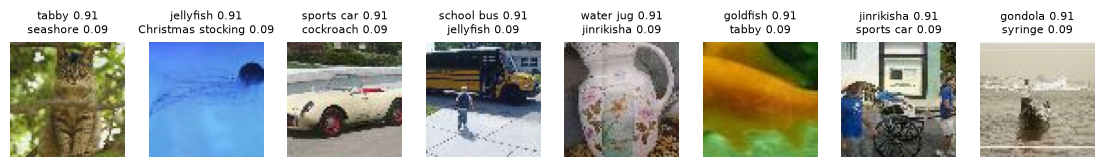

In [6]:
# A training batch as the model receives it (with MixUp the two largest label weights are shown)
images, targets = next(iter(train_ds))
plt.figure(figsize=(14, 2.6))
for i in range(8):
    top2 = np.argsort(targets[i].numpy())[-2:][::-1]
    weights = targets[i].numpy()[top2]
    title = f"{class_names[top2[0]]} {weights[0]:.2f}"
    if weights[1] > 0.01:
        title += f"\n{class_names[top2[1]]} {weights[1]:.2f}"
    plt.subplot(1, 8, i + 1)
    plt.imshow(images[i].numpy().astype("uint8"))
    plt.title(title, fontsize=8)
    plt.axis("off")
plt.show()

## 5. Model
```
64×64 image → augmentation → resize to 224 → ConvNeXt-Tiny (+ its own preprocessing, average pooling)
            → dropout → Dense(200, softmax)
```
* augmentation is only active during training: flip, shift 10 %, zoom 20 %, rotation ±18°, contrast ±20 %
* with mixed precision the backbone computes in float16; augmentation and the output layer stay float32
* `compile_model`: AdamW (no weight decay on biases and normalisation parameters), cross-entropy with label smoothing,
  accuracy and top-5 accuracy

In [7]:
def build_model():
    """Returns (model, backbone). The dtype policy is read when layers are created."""
    keras.mixed_precision.set_global_policy("mixed_float16" if MIXED_PRECISION else "float32")

    augment = keras.Sequential([                          # float32: image ops stay precise
        layers.RandomFlip("horizontal", dtype="float32"),
        layers.RandomTranslation(0.1, 0.1, dtype="float32"),
        layers.RandomZoom(0.2, dtype="float32"),
        layers.RandomRotation(0.05, dtype="float32"),     # 0.05 of a full turn = ±18°
        layers.RandomContrast(0.2, dtype="float32"),
    ], name="augment")

    backbone = keras.applications.ConvNeXtTiny(
        include_top=False, include_preprocessing=True, weights="imagenet",
        input_shape=(INPUT_SIZE, INPUT_SIZE, 3), pooling="avg")

    inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x = augment(inputs)
    x = layers.Resizing(INPUT_SIZE, INPUT_SIZE, dtype="float32")(x)
    x = backbone(x)
    x = layers.Dropout(DROPOUT)(x)
    outputs = layers.Dense(N_CLASSES, activation="softmax", dtype="float32", name="classifier")(x)
    model = keras.Model(inputs, outputs, name="convnext_tiny_classifier")

    keras.mixed_precision.set_global_policy("float32")
    return model, backbone


def compile_model(model, learning_rate, weight_decay):
    optimizer = keras.optimizers.AdamW(learning_rate=learning_rate, weight_decay=weight_decay)
    optimizer.exclude_from_weight_decay(var_names=["bias", "gamma", "beta"])
    model.compile(
        optimizer=optimizer,
        loss=keras.losses.CategoricalCrossentropy(label_smoothing=LABEL_SMOOTHING),
        metrics=[keras.metrics.CategoricalAccuracy(name="accuracy"),
                 keras.metrics.TopKCategoricalAccuracy(k=5, name="top5_accuracy")],
    )


def set_backbone_trainable(backbone, trainable):
    """Set every layer explicitly (not only backbone.trainable), so nothing stays frozen by accident."""
    backbone.trainable = trainable
    for layer in backbone.layers:
        layer.trainable = trainable


def count_trainable(model):
    return int(sum(w.numpy().size for w in model.trainable_weights))


keras.backend.clear_session()
keras.utils.set_random_seed(SEED)
model, backbone = build_model()
print(f"total weights: {model.count_params():,}")

111650432/111650432 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
total weights: 27,973,928


## 6. Evaluation and run log
`evaluate(model, name)` scores a model on the validation (or test) split, prints the weakest classes and appends one
row to `results/convnext_runs.csv`.
`tta=True` adds **test-time augmentation**: every image is also predicted mirrored, and the two predictions are averaged.

In [8]:
def predict_proba(model, ds, tta=False):
    probs = model.predict(ds, verbose=0)
    if tta:
        mirrored = ds.map(lambda x, y: (tf.image.flip_left_right(x), y))
        probs = (probs + model.predict(mirrored, verbose=0)) / 2
    return probs


def evaluate(model, name, split="val", tta=False, notes="", show_worst=10):
    ds, y_true = {"val": (val_ds, y_val), "test": (test_ds, y_test)}[split]
    probs = predict_proba(model, ds, tta=tta)
    pred = probs.argmax(axis=1)
    top5 = np.argsort(probs, axis=1)[:, -5:]
    row = {
        "time": pd.Timestamp.now().strftime("%Y-%m-%d %H:%M"),
        "experiment": name + (" +TTA" if tta else ""),
        "split": split,
        "accuracy": round(float((pred == y_true).mean()), 4),
        "top5_accuracy": round(float((top5 == y_true[:, None]).any(axis=1).mean()), 4),
        "macro_f1": round(float(f1_score(y_true, pred, average="macro")), 4),
        "trainable_weights": count_trainable(model),
        "notes": notes,
    }
    os.makedirs(os.path.dirname(RESULTS_PATH), exist_ok=True)
    pd.DataFrame([row]).to_csv(RESULTS_PATH, mode="a", index=False, header=not os.path.exists(RESULTS_PATH))

    print(f"{row['experiment']} [{split}]  acc {row['accuracy']:.4f}  top-5 {row['top5_accuracy']:.4f}  "
          f"macro-F1 {row['macro_f1']:.4f}")
    if show_worst:
        per_class = pd.Series(f1_score(y_true, pred, average=None, labels=range(N_CLASSES)), index=class_names)
        print(f"weakest {show_worst} classes (F1):", ", ".join(f"{n} {v:.2f}" for n, v in per_class.nsmallest(show_worst).items()))
    return row


def plot_history(stage_a, stage_b):
    """Learning curves of both stages; the dashed line marks the start of fine-tuning."""
    history = pd.concat([pd.DataFrame(stage_a.history), pd.DataFrame(stage_b.history)], ignore_index=True)
    epochs = np.arange(1, len(history) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for ax, metric in zip(axes, ["accuracy", "loss"]):
        ax.plot(epochs, history[metric], label="train")
        ax.plot(epochs, history[f"val_{metric}"], label="validation")
        ax.axvline(len(stage_a.history["loss"]) + 0.5, color="grey", linestyle="--", label="start fine-tuning")
        ax.set(title=metric.capitalize(), xlabel="epoch")
        ax.legend()
    plt.show()

## 7. Stage A – train the head (backbone frozen)
The new Dense layer starts random. Training it first stops its large, meaningless early errors from flowing back into
the pre-trained backbone.

In [9]:
set_backbone_trainable(backbone, False)
compile_model(model, learning_rate=HEAD_LR, weight_decay=1e-4)
print(f"trainable weights: {count_trainable(model):,} (head only)")

history_head = model.fit(train_ds, validation_data=val_ds, epochs=HEAD_EPOCHS)

trainable weights: 153,800 (head only)
Epoch 1/10


I0000 00:00:1795104949.128421    1691 cuda_dnn.cc:461] Loaded cuDNN version 92000
I0000 00:00:1795104949.912973    1691 service.cc:153] XLA service 0x7ec954e97cf0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1795104949.912997    1691 service.cc:161]   StreamExecutor [0]: NVIDIA RTX A6000, Compute Capability 8.6 (Driver: 13.2.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.20.0)
I0000 00:00:1795104951.423881    1691 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


1313/1313 ━━━━━━━━━━━━━━━━━━━━ 111s 72ms/step - accuracy: 0.3300 - loss: 4.0283 - top5_accuracy: 0.5024 - val_accuracy: 0.6204 - val_loss: 2.5744 - val_top5_accuracy: 0.7748
Epoch 2/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 74s 57ms/step - accuracy: 0.4301 - loss: 3.5333 - top5_accuracy: 0.6204 - val_accuracy: 0.6274 - val_loss: 2.5455 - val_top5_accuracy: 0.7806
Epoch 3/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 74s 56ms/step - accuracy: 0.4451 - loss: 3.4567 - top5_accuracy: 0.6371 - val_accuracy: 0.6339 - val_loss: 2.5174 - val_top5_accuracy: 0.7862
Epoch 4/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 74s 56ms/step - accuracy: 0.4530 - loss: 3.4272 - top5_accuracy: 0.6445 - val_accuracy: 0.6329 - val_loss: 2.5194 - val_top5_accuracy: 0.7863
Epoch 5/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 74s 56ms/step - accuracy: 0.4550 - loss: 3.4101 - top5_accuracy: 0.6481 - val_accuracy: 0.6339 - val_loss: 2.5203 - val_top5_accuracy: 0.7859
Epoch 6/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 74s 57ms/step - accuracy: 0.4561 - loss: 3.3899 

## 8. Stage B – fine-tune the whole network
* every ConvNeXt layer becomes trainable (no BatchNorm to protect)
* batch `TRAIN_BATCH = 32` (same as stage A): training all layers keeps far more intermediate results in GPU memory;
  with 64 images per batch Colab's GPU ran out of memory
* learning rate: **warmup** from 0 to `PEAK_LR` in the first epoch, then **cosine decay** to 0
* all epochs run; at the end the best epoch (by `val_accuracy`) is restored and its weights are saved to
  `WEIGHTS_PATH` (Google Drive on Colab, `ConvNeXt_finetune/models/` locally or on a pod)

In [12]:
set_backbone_trainable(backbone, True)

steps_per_epoch = math.ceil(len(labels["train"]) / TRAIN_BATCH)
lr_schedule = keras.optimizers.schedules.CosineDecay(
    initial_learning_rate=0.0,
    warmup_target=PEAK_LR,
    warmup_steps=WARMUP_EPOCHS * steps_per_epoch,
    decay_steps=(FINETUNE_EPOCHS - WARMUP_EPOCHS) * steps_per_epoch,
)
compile_model(model, learning_rate=lr_schedule, weight_decay=WEIGHT_DECAY)
print(f"trainable weights: {count_trainable(model):,} (whole network), batch {TRAIN_BATCH}")

os.makedirs(os.path.dirname(WEIGHTS_PATH), exist_ok=True)
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_accuracy", mode="max", patience=EARLY_STOP_PATIENCE,
                                  restore_best_weights=True, verbose=1),
    keras.callbacks.ModelCheckpoint(WEIGHTS_PATH, monitor="val_accuracy", mode="max",
                                    save_best_only=True, save_weights_only=True),
]
history_ft = model.fit(train_ds, validation_data=val_ds, epochs=FINETUNE_EPOCHS, callbacks=callbacks)

trainable weights: 27,973,928 (whole network), batch 32
Epoch 1/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 292s 193ms/step - accuracy: 0.5668 - loss: 2.9734 - top5_accuracy: 0.7422 - val_accuracy: 0.6909 - val_loss: 2.2855 - val_top5_accuracy: 0.8256
Epoch 2/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 227s 173ms/step - accuracy: 0.6190 - loss: 2.7521 - top5_accuracy: 0.7816 - val_accuracy: 0.6909 - val_loss: 2.2576 - val_top5_accuracy: 0.8288
Epoch 3/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 224s 171ms/step - accuracy: 0.6546 - loss: 2.6097 - top5_accuracy: 0.8082 - val_accuracy: 0.6982 - val_loss: 2.2202 - val_top5_accuracy: 0.8333
Epoch 4/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 225s 171ms/step - accuracy: 0.6799 - loss: 2.5014 - top5_accuracy: 0.8225 - val_accuracy: 0.7067 - val_loss: 2.1904 - val_top5_accuracy: 0.8379
Epoch 5/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 227s 173ms/step - accuracy: 0.7070 - loss: 2.4080 - top5_accuracy: 0.8393 - val_accuracy: 0.7020 - val_loss: 2.2015 - val_top5_accuracy: 0.8369
Epoch 6/10
131

## 9. Results on the validation set
With MixUp the **train** accuracy is measured on blended images, so it can be lower than validation – judge the model
by the validation scores. The second line is the same model with test-time augmentation (mirror + average).

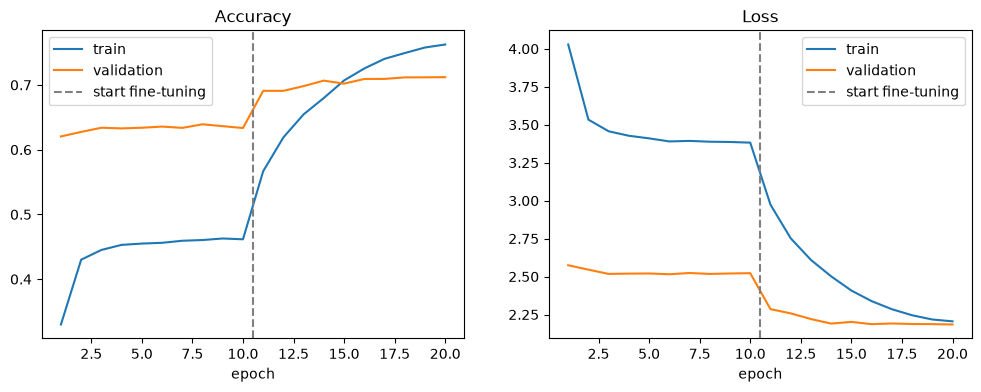

E7-ConvNeXtTiny [val]  acc 0.7120  top-5 0.8401  macro-F1 0.6757
weakest 10 classes (F1): mashed potato 0.21, barrel 0.33, lakeside 0.33, CD player 0.39, reel 0.39, apron 0.40, umbrella 0.41, torch 0.44, pole 0.44, trilobite 0.45
E7-ConvNeXtTiny +TTA [val]  acc 0.7148  top-5 0.8426  macro-F1 0.6784


,time,experiment,split,accuracy,top5_accuracy,macro_f1,trainable_weights,notes
0,2026-11-19 17:15,E7-ConvNeXtTiny,val,0.7120,0.8401,0.6757,27973928,"224px, full fine-tune, head 10ep, cosine 10ep ..."
1,2026-11-19 17:15,E7-ConvNeXtTiny +TTA,val,0.7148,0.8426,0.6784,27973928,"224px, full fine-tune, head 10ep, cosine 10ep ..."


In [13]:
plot_history(history_head, history_ft)

best_epoch = int(np.argmax(history_ft.history["val_accuracy"])) + 1
notes = (f"{INPUT_SIZE}px, full fine-tune, head {HEAD_EPOCHS}ep, cosine {FINETUNE_EPOCHS}ep peak {PEAK_LR}, "
         f"wd {WEIGHT_DECAY}, ls {LABEL_SMOOTHING}, mixup {MIXUP_ALPHA}, best epoch {best_epoch}")
evaluate(model, RUN_NAME, notes=notes)
evaluate(model, RUN_NAME, tta=True, notes=notes, show_worst=0)
pd.read_csv(RESULTS_PATH)

## 10. Final test (run once, at the very end)
The test split is only for the **final** model, after all decisions were made on the validation set.
Set `RUN_TEST = True` only then. Remember: about 10 % of the labels in every split are wrong,
so no model can reach 100 %.

In [14]:
RUN_TEST = True

if RUN_TEST:
    evaluate(model, RUN_NAME, split="test", notes="final test")
    evaluate(model, RUN_NAME, split="test", tta=True, notes="final test", show_worst=0)
else:
    print("Test split not used (RUN_TEST = False).")

E7-ConvNeXtTiny [test]  acc 0.7002  top-5 0.8266  macro-F1 0.6626
weakest 10 classes (F1): lakeside 0.22, golden retriever 0.32, pretzel 0.33, walking stick 0.38, vestment 0.38, picket fence 0.38, Chihuahua 0.40, meat loaf 0.40, magnetic compass 0.41, steel arch bridge 0.41
E7-ConvNeXtTiny +TTA [test]  acc 0.7017  top-5 0.8311  macro-F1 0.6635


## 11. Keep the results (Colab)
The Colab disk is wiped when the session ends. This uploads the run log to the `checkpoints` branch on GitHub
(the weights file is ~110 MB, above GitHub's 100 MB limit, so section 2 saves it to Google Drive instead).
Locally and on a RunPod pod nothing is uploaded: the files are in `ConvNeXt_finetune/results/` and `ConvNeXt_finetune/models/`. On a pod, run `pull_results.ps1` BEFORE terminating it (see the README).

In [15]:
if IN_COLAB:
    from utils import config
    from utils.github_sync import push_files
    if config.ensure_github():
        push_files({RESULTS_PATH: RESULTS_PATH}, f"results: {RUN_NAME}")
    else:
        print("No GitHub token - results stay on this VM only.")
elif ON_POD:
    print("Results stay on the pod. Copy them to your PC BEFORE terminating it: run pull_results.ps1 (see the README).")
    print(f"  run log: {RESULTS_PATH}")
    print(f"  weights: {WEIGHTS_PATH}")
else:
    print(f"Local run - results in {RESULTS_PATH}, weights in {WEIGHTS_PATH}")

Results stay on the pod. Copy them to your PC BEFORE terminating it: run pull_results.ps1 (see the README).
  run log: ConvNeXt_finetune/results/convnext_runs.csv
  weights: ConvNeXt_finetune/models/E7-ConvNeXtTiny.weights.h5


## Notes
Fill in after running:
* stage A (head only) – val accuracy after 3 epochs (E6 frozen reached 65.2 %):
* stage B – best val accuracy / top-5 / macro-F1, best epoch:
* with TTA:
* train vs. validation gap – still overfitting?
* time per epoch:
* next step: